# 03 · ¿Las promociones generan venta incremental?

**Pregunta de negocio.** Una de cada cinco combinaciones tienda × categoría × día tiene una
promoción activa. ¿Venden más esos días? Si no, ¿qué hacemos con el programa?

**Cómo leer este notebook.** La lógica vive en `src/retail_analytics/promotions.py` (con tests
que verifican que el método recupera un efecto conocido). Cada sección cierra con una
**conclusión**.

| # | Sección |
|---|---|
| 1 | Por qué esto se puede tratar como un experimento |
| 2 | ¿La promoción se asignó al azar? |
| 3 | Efecto de la promoción |
| 4 | ¿Qué tamaño de efecto podemos descartar? |
| 5 | ¿Funciona en algún segmento? |
| 6 | La trampa de las transacciones infladas |
| 7 | Implicaciones de negocio y siguiente experimento |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retail_analytics import promotions as pm
from retail_analytics import viz
from retail_analytics.cleaning import build_clean_panel
from retail_analytics.io import load_raw

viz.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

raw = load_raw()
panel = build_clean_panel(raw.transactions, raw.stores, raw.calendar)
d = pm.prepare(panel)
print(f"Filas analizadas: {len(d):,} · con promoción: {d['has_promotion'].mean():.1%}")

Filas analizadas: 203,958 · con promoción: 20.0%


## 1 · Por qué esto se puede tratar como un experimento

Para medir el efecto de una promoción hay que comparar contra lo que se **hubiera vendido sin
ella**. Ese contrafactual no se observa; se aproxima con días comparables sin promoción.

Si las promociones se pusieran a propósito en días buenos (o malos), la comparación estaría
sesgada. Pero si se asignan **como al azar**, los días sin promoción de la misma tienda,
categoría y mes son un buen contrafactual, como en una prueba A/B.

**Método.** Regresión del logaritmo de la venta contra la bandera de promoción, con **efectos
fijos** de tienda × categoría × mes (controla tamaño, categoría y estacionalidad), día de la
semana y festivo. Los errores estándar se **agrupan por tienda** porque los días de una misma
tienda comparten choques. En logaritmo, el coeficiente se lee como cambio porcentual.

## 2 · ¿La promoción se asignó al azar?

Dos tipos de prueba:

1. **Balance:** la tasa de promoción no debería depender del día, formato, categoría, región,
   mes, quincena ni festivo (chi-cuadrada).
2. **Prueba A/A:** una promoción no puede cambiar lo que se vendió **la semana anterior**. Si
   los días con promoción ya vendían distinto una semana antes, las promociones se estarían
   poniendo a propósito en días fuertes o débiles.

In [2]:
pm.assignment_balance(d)

,prueba,estadístico,p_valor,detalle
0,Tasa de promoción por day_of_week,3.4300,0.7527,tasa entre 19.7% y 20.3%
1,Tasa de promoción por store_format,0.3100,0.8549,tasa entre 19.9% y 20.1%
2,Tasa de promoción por category,1.2700,0.9382,tasa entre 19.9% y 20.2%
3,Tasa de promoción por region,4.7300,0.3158,tasa entre 19.7% y 20.2%
4,Tasa de promoción por month,8.6600,0.6529,tasa entre 19.7% y 20.5%
5,Tasa de promoción por is_payday,0.5000,0.4810,tasa entre 20.0% y 20.2%
6,Tasa de promoción por is_holiday,0.7500,0.3860,tasa entre 19.6% y 20.0%
7,Venta de la semana previa (prueba A/A),0.0600,0.9533,diferencia +0.01%


> **Conclusión.** Ninguna prueba rechaza la aleatoriedad (todos los p-valores > 0.3) y la venta
> de la semana previa es idéntica con y sin promoción (+0.01%). La asignación se comporta como
> un experimento aleatorio: la comparación es válida.

## 3 · Efecto de la promoción

In [3]:
metricas = {
    "log_amount_total": "Monto vendido (MXN)",
    "log_units_sold": "Unidades",
    "log_unit_price": "Precio por unidad",
    "log_transactions_clean": "Transacciones reales",
    "log_avg_ticket": "Ticket promedio",
}
efectos = pd.DataFrame({nombre: pm.fixed_effects_effect(d, col) for col, nombre in metricas.items()}).T
efectos["efecto mínimo detectable"] = efectos["se"].map(pm.minimum_detectable_effect)
efectos[["efecto", "ic_inf", "ic_sup", "p_valor", "efecto mínimo detectable", "n"]].style.format(
    {"efecto": "{:+.2%}", "ic_inf": "{:+.2%}", "ic_sup": "{:+.2%}", "p_valor": "{:.3f}",
     "efecto mínimo detectable": "{:.2%}", "n": "{:,.0f}"}
)

,efecto,ic_inf,ic_sup,p_valor,efecto mínimo detectable,n
Monto vendido (MXN),-0.22%,-0.43%,-0.00%,0.046,0.30%,"203,958"
Unidades,+0.05%,-0.25%,+0.36%,0.726,0.43%,"197,840"
Precio por unidad,-0.27%,-0.57%,+0.03%,0.078,0.43%,"197,840"
Transacciones reales,-0.09%,-0.26%,+0.07%,0.274,0.23%,"203,958"
Ticket promedio,-0.12%,-0.26%,+0.01%,0.073,0.19%,"203,958"


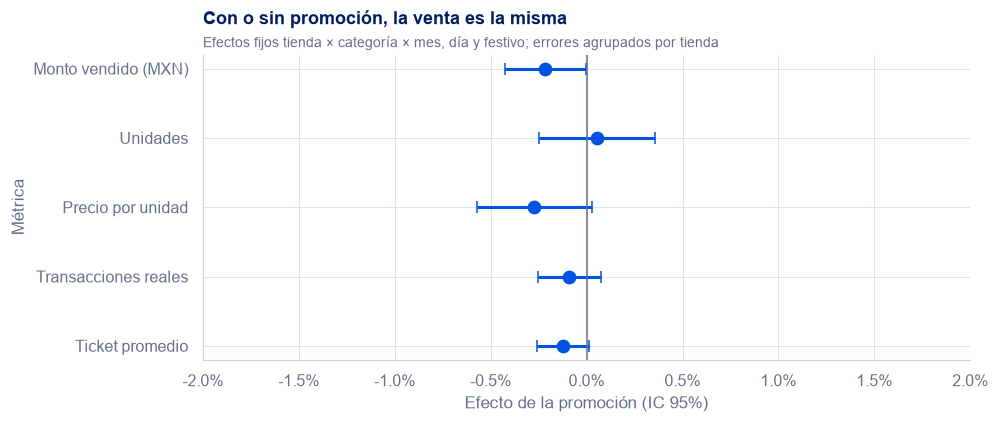

In [4]:
e = efectos.reset_index(names="metrica")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.errorbar(e["efecto"], range(len(e)), xerr=[e["efecto"] - e["ic_inf"], e["ic_sup"] - e["efecto"]],
            fmt="o", color=viz.PRIMARY_BLUE, ecolor=viz.PRIMARY_BLUE, elinewidth=2, capsize=4, markersize=8)
ax.axvline(0, color=viz.INK_2, linewidth=1)
ax.set_yticks(range(len(e)), e["metrica"])
ax.invert_yaxis()
ax.set_xlim(-0.02, 0.02)
viz.fmt_pct(ax, axis="x", decimals=1)
ax.set(xlabel="Efecto de la promoción (IC 95%)", ylabel="Métrica")
ax.set_title("Con o sin promoción, la venta es la misma")
viz.subtitle(ax, "Efectos fijos tienda × categoría × mes, día y festivo; errores agrupados por tienda")
plt.show()

> **Conclusión.** Ninguna métrica se mueve de forma relevante. El monto vendido cambia −0.2%
> (IC 95%: −0.4% a 0.0%, p = 0.046): ligeramente a la baja, sin relevancia económica. **No hay más unidades, ni más
> transacciones, ni un descuento medible en el precio**.
>
> Esto último es lo más revelador: una promoción que no cambia el precio ni el volumen sugiere
> que **la promoción no se está ejecutando en tienda** o que **la bandera se registra mal**.

## 4 · ¿Qué tamaño de efecto podemos descartar?

Que algo no sea significativo no prueba que el efecto sea cero: puede que el experimento sea
demasiado pequeño para verlo. El **efecto mínimo detectable** (MDE, 80% de potencia, 5% de
significancia) dice qué tan grande tendría que ser el efecto para que lo hubiéramos visto.

In [5]:
mde = efectos.loc["Monto vendido (MXN)", "efecto mínimo detectable"]
sup = efectos.loc["Monto vendido (MXN)", "ic_sup"]
print(f"Efecto mínimo detectable en monto: {mde:.2%}")
print(f"Límite superior del IC 95%: {sup:+.2%}")

Efecto mínimo detectable en monto: 0.30%
Límite superior del IC 95%: -0.00%


> **Conclusión.** Con ~200 mil observaciones, este análisis detectaría un efecto de apenas
> **0.3%**. El límite superior del intervalo es ~0%. Podemos afirmar con confianza que **las
> promociones no generan ni 0.5% de venta adicional**, muy por debajo de lo que cualquier
> promoción necesita para pagarse.

## 5 · ¿Funciona en algún segmento?

Un efecto nulo en promedio podría esconder segmentos donde sí funciona y otros donde resta. Se
estima el efecto por separado en cada formato, categoría, región, nivel socioeconómico, fin de
semana, quincena y temporada. Como se prueban muchos segmentos, algunos saldrían
"significativos" por azar: se corrige con **Benjamini-Hochberg** (controla la proporción de
falsos descubrimientos).

In [6]:
panel_seg = d.assign(
    fin_de_semana=np.where(d["is_weekend"], "Sí", "No"),
    quincena=np.where(d["is_payday"], "Sí", "No"),
    temporada_alta=np.where(d["month"].isin([11, 12]), "Nov-Dic", "Resto"),
)
het = pm.heterogeneity(
    panel_seg, "log_amount_total",
    ["store_format", "category", "region", "socioeconomic_level", "fin_de_semana", "quincena", "temporada_alta"],
)
het["significativo (ajustado)"] = het["p_ajustado"] < 0.05
het[["segmento", "valor", "efecto", "ic_inf", "ic_sup", "p_valor", "p_ajustado", "significativo (ajustado)"]].style.format(
    {"efecto": "{:+.2%}", "ic_inf": "{:+.2%}", "ic_sup": "{:+.2%}", "p_valor": "{:.3f}", "p_ajustado": "{:.3f}"}
)

,segmento,valor,efecto,ic_inf,ic_sup,p_valor,p_ajustado,significativo (ajustado)
0,store_format,Express,-0.08%,-0.46%,+0.29%,0.658,0.787,False
1,store_format,Bodega,-0.20%,-0.50%,+0.11%,0.208,0.500,False
2,store_format,Supercenter,-0.45%,-0.91%,+0.00%,0.051,0.189,False
3,category,Abarrotes,-0.22%,-0.76%,+0.32%,0.428,0.642,False
4,category,Bebidas,-0.01%,-0.56%,+0.55%,0.978,0.978,False
5,category,Cuidado_Personal,-0.29%,-0.86%,+0.28%,0.315,0.581,False
6,category,Electronica,-0.69%,-1.15%,-0.22%,0.004,0.095,False
7,category,Hogar,+0.07%,-0.49%,+0.63%,0.812,0.847,False
8,category,Ropa,-0.14%,-0.70%,+0.43%,0.641,0.787,False
9,region,Centro,-0.28%,-0.92%,+0.36%,0.387,0.627,False


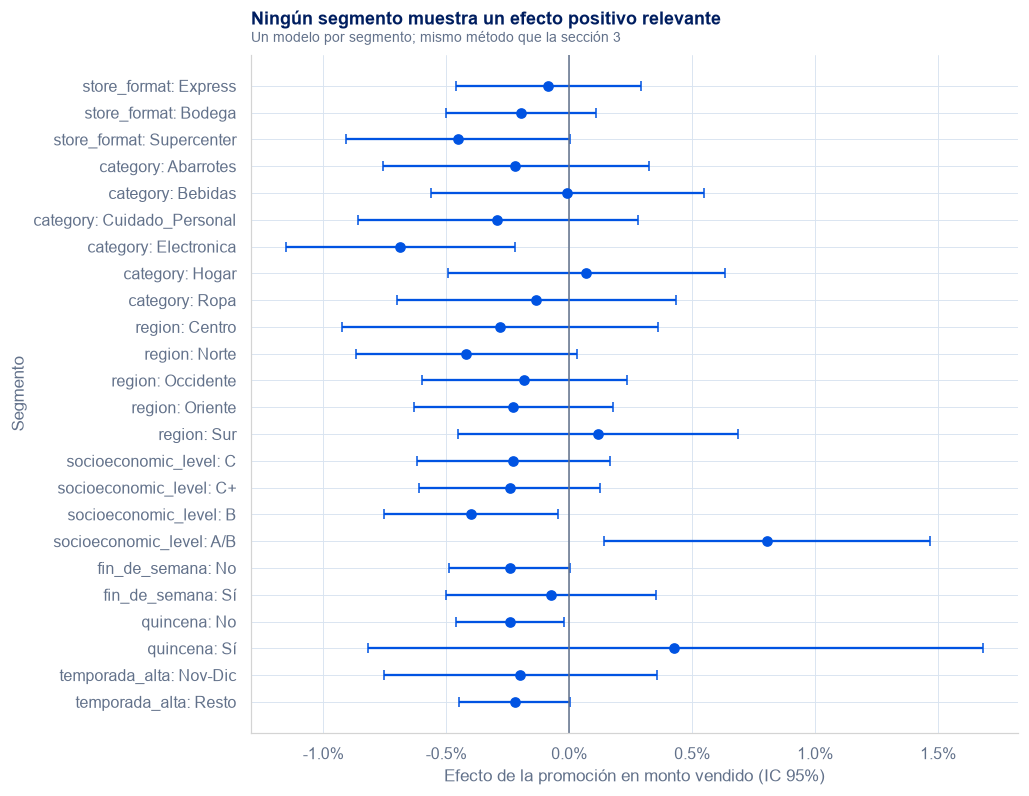

In [7]:
h = het.assign(etiqueta=het["segmento"] + ": " + het["valor"])
fig, ax = plt.subplots(figsize=(9, 8))
ax.errorbar(h["efecto"], range(len(h)), xerr=[h["efecto"] - h["ic_inf"], h["ic_sup"] - h["efecto"]],
            fmt="o", color=viz.PRIMARY_BLUE, ecolor=viz.PRIMARY_BLUE, elinewidth=1.5, capsize=3, markersize=6)
ax.axvline(0, color=viz.INK_2, linewidth=1)
ax.set_yticks(range(len(h)), h["etiqueta"])
ax.invert_yaxis()
viz.fmt_pct(ax, axis="x", decimals=1)
ax.set(xlabel="Efecto de la promoción en monto vendido (IC 95%)", ylabel="Segmento")
ax.set_title("Ningún segmento muestra un efecto positivo relevante")
viz.subtitle(ax, "Un modelo por segmento; mismo método que la sección 3")
plt.show()

> **Conclusión.** Ningún segmento sale significativo después de corregir por pruebas múltiples.
> Sin corregir, 4 de 24 segmentos tienen p < 0.05 (Electrónica −0.7%, nivel B −0.4%, días sin
> quincena −0.2% y nivel A/B +0.8%): al probar tantos segmentos es esperable que algunos salgan así
> por azar, y con la corrección ninguno sobrevive (el menor p ajustado es 0.095). El único positivo
> es A/B, y aun si fuera real, +0.8% en el 9% de la venta no cambia la conclusión. **No hay un
> segmento donde convenga focalizar la promoción.**

## 6 · La trampa de las transacciones infladas

Si alguien mide el programa con `total_transactions` (el campo que reporta el sistema), llega a
la conclusión contraria:

In [8]:
d["log_total_transactions_reported"] = np.log(d["total_transactions_reported"].astype(float))
trampa = pd.DataFrame(
    {
        "Transacciones reportadas (campo del sistema)": pm.fixed_effects_effect(d, "log_total_transactions_reported"),
        "Transacciones reales (efectivo + tarjeta)": pm.fixed_effects_effect(d, "log_transactions_clean"),
    }
).T
trampa[["efecto", "ic_inf", "ic_sup"]].style.format("{:+.2%}")

,efecto,ic_inf,ic_sup
Transacciones reportadas (campo del sistema),+21.91%,+21.71%,+22.11%
Transacciones reales (efectivo + tarjeta),-0.09%,-0.26%,+0.07%


> **Conclusión.** El campo del sistema muestra +22% de transacciones con promoción; el conteo
> real, 0%. Las transacciones "extra" no tienen medio de pago ni dinero detrás (EDA, sección 4).
> **Cualquier tablero que reporte el éxito de las promociones con ese campo está sobreestimando
> su impacto.**

## 7 · Implicaciones de negocio y siguiente experimento

In [9]:
venta_promo = d.loc[d["has_promotion"] == 1, "amount_total"].sum()
venta_total = d["amount_total"].sum()
meses = d["date"].dt.to_period("M").nunique()
print(f"Venta en días con promoción: {venta_promo / 1e6:,.0f} M MXN ({venta_promo / venta_total:.1%} de la venta) en {meses} meses")
ef = efectos.loc["Monto vendido (MXN)"]
print(f"Venta incremental atribuible: {venta_promo * ef['efecto'] / 1e6:+,.0f} M MXN "
      f"(IC 95%: {venta_promo * ef['ic_inf'] / 1e6:+,.0f} a {venta_promo * ef['ic_sup'] / 1e6:+,.0f} M MXN), es decir, ligeramente negativo (p ≈ 0.05) y económicamente nulo")

Venta en días con promoción: 6,953 M MXN (20.0% de la venta) en 14 meses
Venta incremental atribuible: -15 M MXN (IC 95%: -30 a -0 M MXN), es decir, ligeramente negativo (p ≈ 0.05) y económicamente nulo


In [10]:
# Tamaño del siguiente piloto: cuántos días tienda-categoría por grupo para detectar +2% en monto.
from scipy import stats

resid_sd = (d["log_amount_total"] - d.groupby(["store_id", "category", "ym", "day_of_week"])["log_amount_total"].transform("mean")).std()
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.8)
for objetivo in (0.01, 0.02, 0.05):
    n = 2 * (z * resid_sd / np.log1p(objetivo)) ** 2
    print(f"Para detectar +{objetivo:.0%}: ~{n:,.0f} días tienda-categoría por grupo (promoción y control)")

Para detectar +1%: ~8,217 días tienda-categoría por grupo (promoción y control)
Para detectar +2%: ~2,075 días tienda-categoría por grupo (promoción y control)
Para detectar +5%: ~342 días tienda-categoría por grupo (promoción y control)


### Lectura para el negocio

1. **El programa de promociones, como está registrado hoy, no genera venta incremental.** Cerca
   del 20% de la venta ocurre en días con promoción, y el efecto atribuible es ligeramente negativo
   (−0.2%, p ≈ 0.05) y económicamente nulo: podemos descartar efectos positivos mayores a ~0.3%.
2. **No se observa descuento en precio**, así que el problema no parece ser que la promoción
   "regale margen", sino que **no llega al anaquel** o **no se registra correctamente**.
3. **El campo de transacciones del sistema infla en ~22% los días de promoción** y hace parecer
   exitoso un programa que no mueve la venta.

### Recomendaciones

| # | Acción | Responsable sugerido |
|---|---|---|
| 1 | **Auditar la ejecución**: en una muestra de tiendas, verificar si las promociones marcadas están en anaquel y con precio | Operaciones / comercial |
| 2 | **Corregir el conteo de transacciones** en días de promoción y dejar de usar `total_transactions` para medir campañas | Sistemas de punto de venta |
| 3 | **Rediseñar la siguiente campaña como prueba A/B**: asignación aleatoria por tienda, indicador definido de antemano (monto vendido) y tamaño de muestra calculado arriba | Comercial + analítica |
| 4 | **Pausar o reducir el programa** hasta tener evidencia de que funciona, y reasignar el presupuesto a palancas con efecto medido | Dirección comercial |

**Limitaciones.** No hay datos del costo de las promociones ni del tipo de mecánica (descuento,
2x1, exhibición), así que no se puede estimar el retorno en pesos ni comparar mecánicas. El
análisis asume que la bandera `has_promotion` describe bien cuándo hubo promoción: si esa bandera
está mal registrada, la conclusión es sobre el registro y no sobre las promociones, y por eso la
primera recomendación es auditar.